<a href="https://colab.research.google.com/github/sen-soumya/Optical-communication/blob/main/Coherent%20Optical%20Signal%20Condition%20Characterization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Setup & Imports

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

np.random.seed(42)

### 2. Channel Simulation Engine

In [7]:
def generate_coherent_channel(num_symbols=1500, condition="Normal", snr_db=22, linewidth_khz=100, nl_factor=0.0):
    """
    Simulates a coherent optical link generating 16-QAM signals
    corrupted by noise, phase drift, non-linearities, and bandwidth constraints.
    """
    points = np.array([-3, -1, 1, 3])
    x, y = np.meshgrid(points, points)
    constellation = (x + 1j * y) / np.sqrt(10)

    random_indices = np.random.choice(16, num_symbols)
    tx_symbols = constellation.flatten()[random_indices]

    snr_linear = 10 ** (snr_db / 10)
    noise_var = 1.0 / snr_linear
    noise = np.sqrt(noise_var / 2) * (np.random.normal(size=num_symbols) + 1j * np.random.normal(size=num_symbols))
    rx_signal = tx_symbols + noise

    symbol_rate = 32e9
    phase_var = 2 * np.pi * (linewidth_khz * 1e3) * (1.0 / symbol_rate)
    phase_drift = np.cumsum(np.random.normal(0, np.sqrt(phase_var), num_symbols))
    rx_signal = rx_signal * np.exp(1j * phase_drift)

    rx_signal = rx_signal * np.exp(1j * nl_factor * (np.abs(rx_signal) ** 2))

    if condition == "Bandwidth_Limited":
        rx_signal = np.convolve(rx_signal, [0.7, 0.25, 0.05], mode='same')

    return rx_signal, tx_symbols

### 3. Feature Extraction

In [8]:
def extract_optical_features(rx_signal, tx_symbols):
    """
    Extracts statistical structural features from raw received complex vectors.
    """
    amplitude = np.abs(rx_signal)
    phase = np.angle(rx_signal)

    received_power = np.mean(amplitude ** 2)
    phase_variance = np.var(phase)
    papr = np.max(amplitude ** 2) / received_power

    rmse = np.sqrt(np.mean((np.abs(rx_signal - tx_symbols)) ** 2))
    evm_pct = (rmse / np.max(np.abs(tx_symbols))) * 100

    return [
        np.mean(amplitude),
        np.var(amplitude),
        phase_variance,
        received_power,
        papr,
        evm_pct
    ]
def generate_coherent_channel(num_symbols=1500, condition="Normal", snr_db=22, linewidth_khz=100, nl_factor=0.0):
    """
    Simulates a coherent optical link generating 16-QAM signals
    corrupted by varying noise, phase drift, non-linearities, and bandwidth constraints.
    """
    # 1. 16-QAM Constellation Generation
    points = np.array([-3, -1, 1, 3])
    x, y = np.meshgrid(points, points)
    constellation = (x + 1j * y) / np.sqrt(10) # Normalize average power to 1

    random_indices = np.random.choice(16, num_symbols)
    tx_symbols = constellation.flatten()[random_indices]

    # 2. Additive White Gaussian Noise (AWGN)
    snr_linear = 10 ** (snr_db / 10)
    noise_var = 1.0 / snr_linear
    noise = np.sqrt(noise_var / 2) * (np.random.normal(size=num_symbols) + 1j * np.random.normal(size=num_symbols))
    rx_signal = tx_symbols + noise

    # 3. Laser Phase Noise (Wiener Process / Laser Linewidth)
    symbol_rate = 32e9 # 32 GBaud
    phase_var = 2 * np.pi * (linewidth_khz * 1e3) * (1.0 / symbol_rate)
    phase_drift = np.cumsum(np.random.normal(0, np.sqrt(phase_var), num_symbols))
    rx_signal = rx_signal * np.exp(1j * phase_drift)

    # 4. Kerr Non-linear Distortion (Self-Phase Modulation proxy)
    rx_signal = rx_signal * np.exp(1j * nl_factor * (np.abs(rx_signal) ** 2))

    # 5. Bandwidth Limitation (Memory/ISI Simulation)
    if condition == "Bandwidth_Limited":
        # Introduce a basic low-pass inter-symbol smearing
        rx_signal = np.convolve(rx_signal, [0.7, 0.25, 0.05], mode='same')

    return rx_signal, tx_symbols

### 4. Dataset Generation

In [9]:
dataset = []
ground_truth_labels = []

# Scenario A: High SNR (Optimal Link)
for _ in range(100):
    rx, tx = generate_coherent_channel(condition="Normal", snr_db=26, linewidth_khz=50, nl_factor=0.0)
    dataset.append(extract_optical_features(rx, tx))
    ground_truth_labels.append("Optimal Link")

# Scenario B: High Phase Noise Link
for _ in range(100):
    rx, tx = generate_coherent_channel(condition="Normal", snr_db=22, linewidth_khz=1200, nl_factor=0.05)
    dataset.append(extract_optical_features(rx, tx))
    ground_truth_labels.append("Severe Phase Drift")

# Scenario C: Severe Bandwidth Constraint
for _ in range(100):
    rx, tx = generate_coherent_channel(condition="Bandwidth_Limited", snr_db=20, linewidth_khz=100, nl_factor=0.0)
    dataset.append(extract_optical_features(rx, tx))
    ground_truth_labels.append("Bandwidth Smear")

columns = ['mean_amp', 'var_amp', 'var_phase', 'rx_power', 'papr', 'evm']
df = pd.DataFrame(dataset, columns=columns)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop(columns=['evm']))

### 5. Unsupervised Clustering (K-Means)

In [10]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

sil_score = silhouette_score(X_scaled, df['cluster'])
print(f"Silhouette Score: {sil_score:.3f}")

Silhouette Score: 0.523


### 6. Anomaly Detection (Isolation Forest)

In [15]:
anomaly_dataset = []
# Extreme Non-linear Saturation Burst
for _ in range(15):
    rx, tx = generate_coherent_channel(condition="Normal", snr_db=14, linewidth_khz=3000, nl_factor=1.8)
    anomaly_dataset.append(extract_optical_features(rx, tx))

df_anomaly = pd.DataFrame(anomaly_dataset, columns=columns)
X_anomaly_scaled = scaler.transform(df_anomaly.drop(columns=['evm']))

iso_forest = IsolationForest(contamination=0.05, random_state=42)
iso_forest.fit(X_scaled)

anomaly_predictions = iso_forest.predict(X_anomaly_scaled)
detected_anomalies = np.sum(anomaly_predictions == -1)
print(f"Isolated {detected_anomalies} out of {len(X_anomaly_scaled)} critical defects.")

Isolated 14 out of 15 critical defects.


### 7. Performance Visualization & Evaluation

,evm,var_phase,Profile
cluster,,,
0,20.814688,3.279208,Severe Phase Drift
1,76.824796,3.251973,Bandwidth Smear
2,13.033272,3.157414,Optimal Link


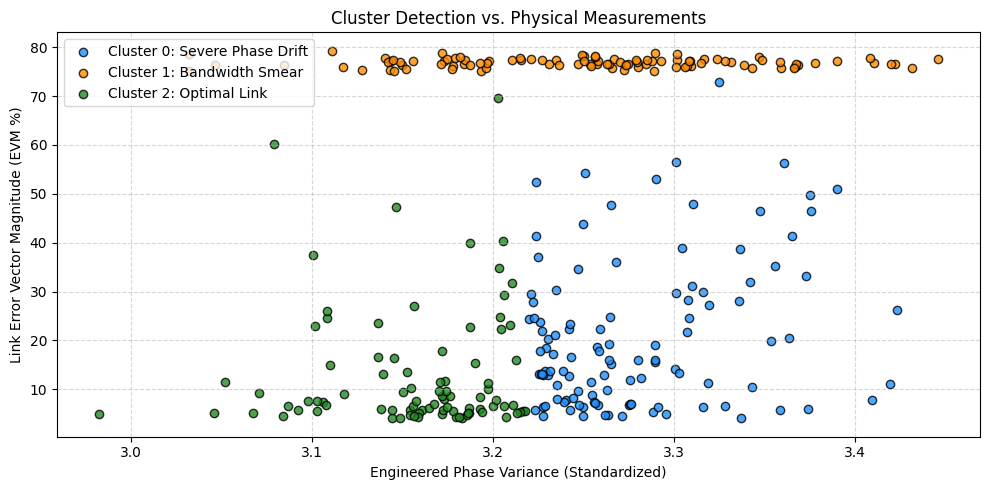

In [16]:
df['ground_truth'] = ground_truth_labels

cluster_summary = df.groupby('cluster').agg({
    'evm': 'mean',
    'var_phase': 'mean',
    'ground_truth': lambda x: x.value_counts().index[0]
}).rename(columns={'ground_truth': 'Profile'})

display(cluster_summary)

plt.figure(figsize=(10, 5))
colors = ['dodgerblue', 'darkorange', 'forestgreen']
for cluster_id in range(3):
    mask = (df['cluster'] == cluster_id)
    plt.scatter(df.loc[mask, 'var_phase'], df.loc[mask, 'evm'],
                label=f"Cluster {cluster_id}: {cluster_summary.loc[cluster_id, 'Profile']}",
                color=colors[cluster_id], alpha=0.8, edgecolors='k')

plt.title("Cluster Detection vs. Physical Measurements")
plt.xlabel("Engineered Phase Variance (Standardized)")
plt.ylabel("Link Error Vector Magnitude (EVM %)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()